# ResNet18: transfer learning, accuracy and compute

Can pretrained visual features improve on our compact CNN? We compare a frozen feature extractor, late-stage adaptation, regularisation and early spatial downsampling.

The retained standard augmented model reaches validation macro-F1 **0.6281**. Stride 1 reaches **0.6303**, with more missed faults and higher compute cost. The small, single-seed gain needs replication.

This notebook reads recorded results and optional local images; the final Grad-CAM section optionally loads the frozen checkpoint for selected validation images. It does not download weights, train a model or evaluate test images. Start with the [CNN baseline](02_baseline_experiments.ipynb); detailed trials remain in the [archive](../archive/README.md).

In [1]:
from pathlib import Path
import sys
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/pv_fault").is_dir():
    raise RuntimeError("Run from the repository root or notebooks folder.")
sys.path.insert(0, str(ROOT / "src"))
from pv_fault.data import CLASS_NAMES, CLASS_TO_INDEX
from pv_fault.plots import learning_curves, confusion_matrix, image_examples

SEED = 2112
manifest_path = ROOT / "data/splits/infrared_solar_modules_v1.csv"
manifest_sha = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
manifest_summary = json.loads(manifest_path.with_suffix(".json").read_text())
assert manifest_sha == manifest_summary["manifest_sha256"]
manifest = pd.read_csv(manifest_path, dtype=str)
assert manifest.groupby("group_id")["split"].nunique().eq(1).all()
validation_rows = manifest.loc[manifest["split"].eq("val")]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.")

from torch import nn
from pv_fault.models.resnet import preprocess_thermal, IMAGENET_MEAN, IMAGENET_STD

fresh = json.loads((ROOT / "results/resnet18-reproduction-v1.json").read_text())
generalisation = json.loads((ROOT / "results/resnet18-generalisation-v1.json").read_text())
spatial = json.loads((ROOT / "results/resnet18-spatial-v1.json").read_text())
cnn = json.loads((ROOT / "results/cnn-error-review-v1.json").read_text())
assert all(record["test_evaluated"] is False for record in (fresh, generalisation, spatial))

Frozen split checked. This notebook reads recorded results; it does not train or evaluate test images.


## 1. What transfer learning changes

ResNet18 starts with ImageNet features learned from colour photographs. We replace its classifier with 12 outputs, first train only that head, then adapt the final residual block (`layer4`). Earlier weights and all BatchNorm statistics/affine parameters remain fixed during late-stage fitting.

Our images have one channel and little spatial detail. The adapter doubles their size from **40 × 24 to 80 × 48**, repeats brightness into three channels and applies ImageNet normalisation. Resizing adds no new image information. Exactly the same adapter is used for fitting and inference.

In [2]:
mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
example = torch.full((1, 1, 40, 24), .5)
adapted = preprocess_thermal(example, mean, std)
assert tuple(adapted.shape) == (1, 3, 80, 48)
head = nn.Linear(512, len(CLASS_NAMES))
assert sum(p.numel() for p in head.parameters()) == 6156
display(pd.DataFrame({"Channel": ["R copy", "G copy", "B copy"],
    "ImageNet mean": IMAGENET_MEAN, "ImageNet std": IMAGENET_STD,
    "Normalised brightness for input 0.5": adapted[0, :, 0, 0].tolist()}).round(3))
print("The frozen phase trains 6,156 head parameters.")

,Channel,ImageNet mean,ImageNet std,Normalised brightness for input 0.5
0,R copy,0.485,0.229,0.066
1,G copy,0.456,0.224,0.196
2,B copy,0.406,0.225,0.418


The frozen phase trains 6,156 head parameters.


## 2. Follow the progression without losing the controls

1. **Frozen head → layer4:** test whether adapting late features helps thermal images.
2. **Learning rates, duration and scheduling:** improve the training recipe; compare complete configurations.
3. **Generalisation experiments:** separately test mild augmentation, smoothing, class weights and extra stage adaptation. Augmentation gives a small validation gain; more adaptation did not settle the remaining errors.
4. **Spatial variants:** apply one stem change at a time under the same late-stage recipe and common frozen parent.

The table is a development history, not an estimate of independent causal effects across all rows. Matched comparisons and negative trials remain in the [optimisation](../results/resnet18-hour-v1.md) and [generalisation](../results/resnet18-generalisation-v1.md) records.

In [3]:
reference = next(run for run in generalisation["runs"] if run["arm"] == "reference")
progression = [(run["label"], run) for run in fresh["experiments"]]
progression += [("Scheduled layer4", reference)]
progression += [(run["arm"], run) for run in spatial["runs"]]
rows = []
for label, run in progression:
    assert run["plan"]["manifest_sha256"] == manifest_sha
    assert run["verification"]["checkpoint_predictions_verified"]
    assert run["metrics"]["count"] == len(validation_rows)
    metrics = run["metrics"]
    rows.append({"Stage": label, "Macro-F1": metrics["macro_f1"], "Accuracy": metrics["accuracy"],
                 "Balanced accuracy": metrics["balanced_accuracy"],
                 "Missed faults / 1492": metrics["faults_called_normal"],
                 "Normal false alarms / 1496": metrics["normal_called_fault"]})
for run in cnn["models"]:
    metrics = run["metrics"]
    rows.append({"Stage": "SmallCNN: " + run["role"], "Macro-F1": metrics["macro_f1"],
        "Accuracy": metrics["accuracy"], "Balanced accuracy": metrics["balanced_accuracy"],
        "Missed faults / 1492": metrics["faults_called_normal"],
        "Normal false alarms / 1496": metrics["normal_called_fault"]})
display(pd.DataFrame(rows).set_index("Stage").round(4))

,Macro-F1,Accuracy,Balanced accuracy,Missed faults / 1492,Normal false alarms / 1496
Stage,,,,,
Fresh frozen ResNet18,0.4900,0.6921,0.4925,299,156
Fresh layer4 ResNet18,0.5629,0.7319,0.5784,184,162
Scheduled layer4,0.6261,0.7908,0.5966,196,55
standard,0.6281,0.7865,0.6046,198,52
stride1,0.6303,0.7895,0.6040,205,51
no_maxpool,0.6229,0.7825,0.6145,159,91
SmallCNN: Fewer missed faults,0.5964,0.7413,0.6183,82,240
SmallCNN: Highest macro-F1,0.6012,0.7634,0.5934,170,112


## 3. Preserve spatial detail: the final controlled comparison

| Variant | First convolution | Initial max pool | Final layer4 grid |
|---|---|---|---|
| Standard + augmentation | 7 × 7, stride 2 | 3 × 3, stride 2 | `512 × 3 × 2` |
| Stride 1 | Same weights, stride 1 | Unchanged | `512 × 5 × 3` |
| No max pool | Unchanged | Identity | `512 × 5 × 3` |

All three use the same seed, frozen-head parent, augmentation, class weights, optimiser, learning rates and schedule. Only layer4 and the classifier train. Mild augmentation applies horizontal flips and contrast changes to training images only. No validation/test augmentation is used.

Neither spatial change adds learned tensors. **A checkpoint must record and restore the variant:** its weights alone cannot identify the stride or pooling setting. The common parent head was fitted with the standard stem, so this comparison does not exhaust stem-specific head refitting or BatchNorm adaptation.

,Batch size,Head LR,Layer4 LR,Epoch cap,Time cap (min),Augmentation
Variant,,,,,,
standard,64,0.0003,0.00003,10,20.0,True
stride1,64,0.0003,0.00003,10,60.0,True
no_maxpool,64,0.0003,0.00003,10,60.0,True


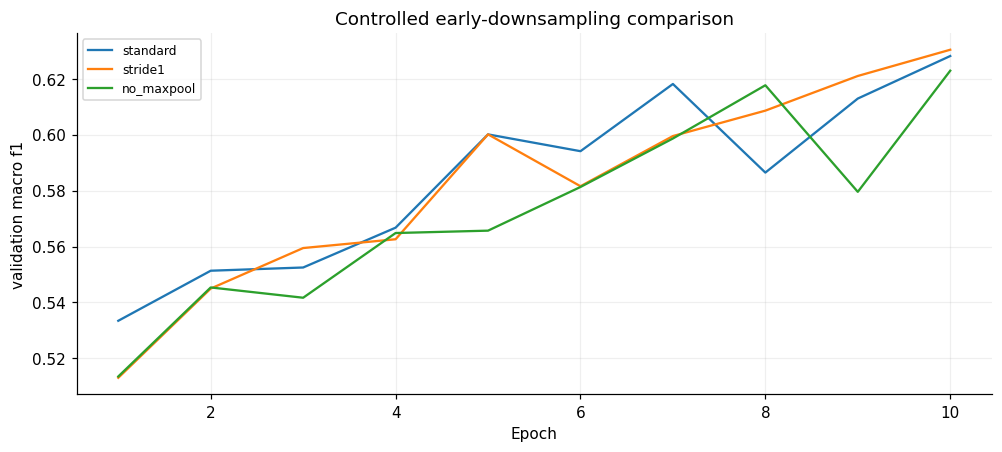

<Axes: title={'center': 'Controlled early-downsampling comparison'}, xlabel='Epoch', ylabel='validation macro f1'>

In [4]:
plan_files = ["experiment-plan-resnet18-generalisation-augmentation.json",
              "experiment-plan-resnet18-spatial-stride1.json",
              "experiment-plan-resnet18-spatial-no_maxpool.json"]
plans = [json.loads((ROOT / "configs" / filename).read_text()) for filename in plan_files]
assert all(plan["manifest_sha256"] == manifest_sha for plan in plans)
display(pd.DataFrame([{"Variant": p.get("spatial_variant", "standard"),
    "Batch size": p["batch_size"], "Head LR": p["head_learning_rate"],
    "Layer4 LR": p["layer4_learning_rate"], "Epoch cap": p["max_epochs"],
    "Time cap (min)": p["max_elapsed_seconds"] / 60,
    "Augmentation": p.get("train_augmentation") is not None} for p in plans]).set_index("Variant"))
learning_curves(spatial["runs"], title="Controlled early-downsampling comparison",
                labels=[run["arm"] for run in spatial["runs"]])

## 4. Inspect class-level errors

The highest-macro-F1 candidate is stride 1. Its confusion matrix uses percentages within each true class, so rare classes remain visible. Compare its recall with the standard model before treating a headline score as an improvement.

The examples are deterministic mistakes from the three weakest classes, selected by image ID. They illustrate failures; they are not a representative sample or evidence that labels are incorrect. Their display is skipped if local images are unavailable.

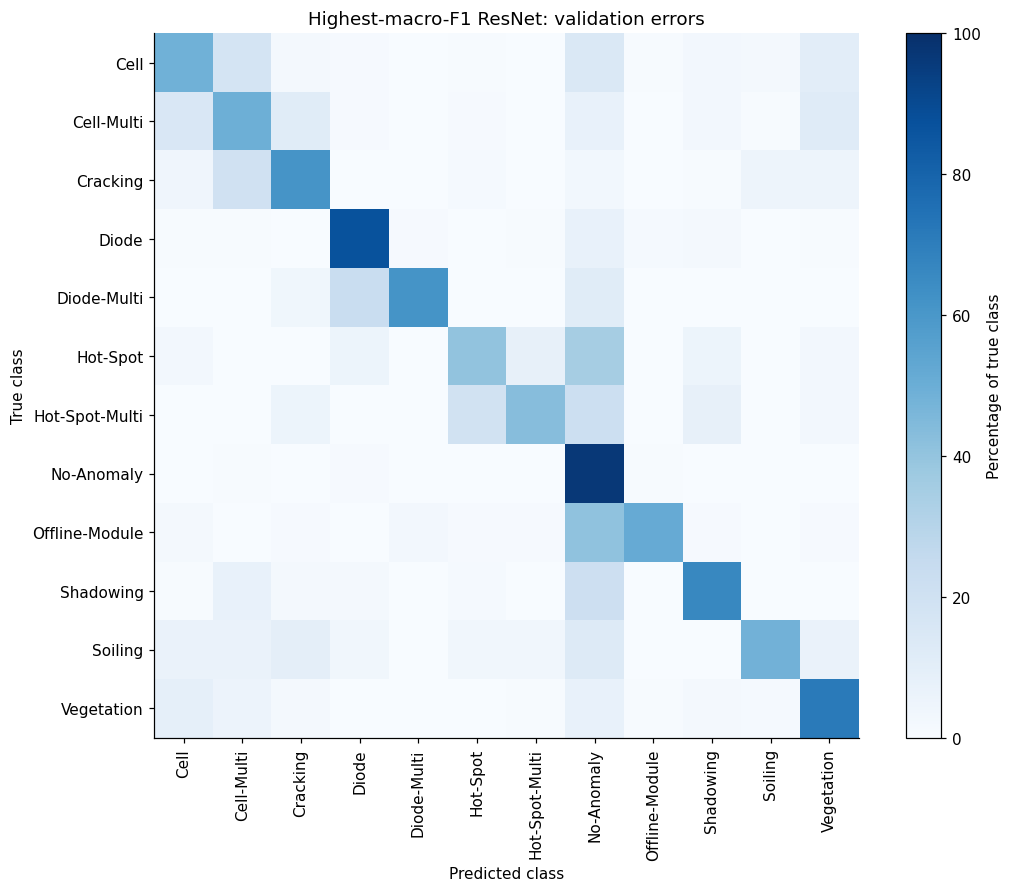

,standard,stride1,Change
Cell,0.561,0.486,-0.075
Cell-Multi,0.425,0.492,0.067
Cracking,0.645,0.610,-0.035
Diode,0.879,0.870,-0.009
Diode-Multi,0.615,0.615,0.000
Hot-Spot,0.514,0.405,-0.108
Hot-Spot-Multi,0.459,0.432,-0.027
No-Anomaly,0.965,0.966,0.001
Offline-Module,0.504,0.512,0.008
Shadowing,0.647,0.660,0.013


,true_label,predicted_label,count,share_of_true_class
0,Offline-Module,No-Anomaly,50,0.406504
1,Cell,Cell-Multi,49,0.175000
2,Cell,No-Anomaly,41,0.146429
3,Shadowing,No-Anomaly,33,0.211538
4,Cell,Vegetation,29,0.103571


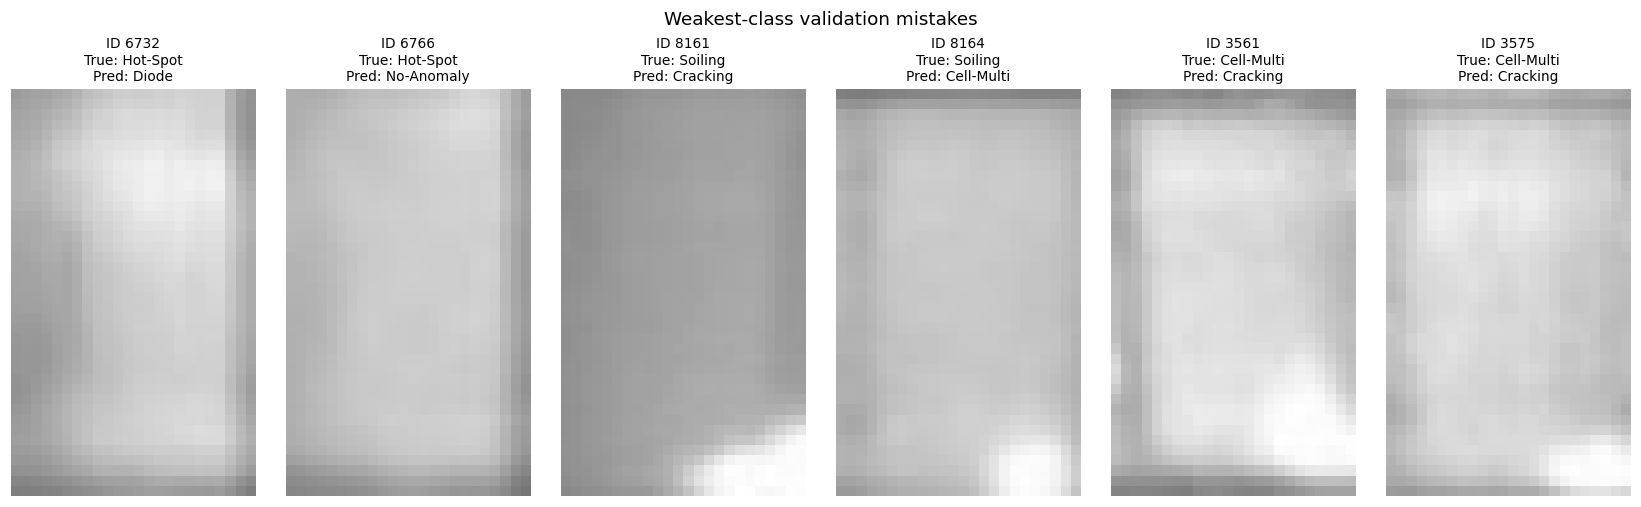

In [5]:
selected = next(run for run in spatial["runs"] if run["run_id"] == spatial["selected_run"])
standard = next(run for run in spatial["runs"] if run["arm"] == "standard")
confusion_matrix(selected["metrics"], "Highest-macro-F1 ResNet: validation errors")
recall = pd.DataFrame({run["arm"]: {label: value["recall"]
    for label, value in run["metrics"]["per_class"].items()} for run in (standard, selected)})
recall["Change"] = recall[selected["arm"]] - recall["standard"]
display(recall.reindex(CLASS_NAMES).round(3))
error_review = spatial["error_review"]
display(pd.DataFrame(error_review["top_confusions"]).head(5))
val_ids = set(validation_rows["image_id"])
assert all(example["image_id"] in val_ids for example in error_review["examples"])
image_examples(error_review["examples"], ROOT / "data/raw", "Weakest-class validation mistakes")

## 5. Account for the compute cost

Parameter count stays constant across ResNet spatial variants; larger activations still increase actual computation. Stride 1 has **11,182,668 total / 8,394,764 trainable parameters**, compared with **47,820** in the selected SmallCNN architecture.

Fit times are historical local CPU measurements, including loading, training, validation and saving; machine load varied. Each workflow reuses a frozen-head parent, whose recorded fitting cost is included separately below. These archived producers ran validation twice per epoch; current code uses one combined pass.

The inference benchmark uses actual checkpoint weights on identical synthetic inputs, four CPU threads, five warmups and twenty timed forwards. It excludes image loading and application overhead. Parameter storage is not peak RAM; energy and FLOPs were not measured.

In [6]:
comparison = pd.DataFrame(spatial["comparison"]).set_index("variant")
display(comparison[["macro_f1", "fit_minutes", "workflow_minutes", "batch_one_ms", "batch64_ms"]].round(4))
benchmark = json.loads((ROOT / "results/resnet18-spatial-v1-inference.json").read_text())
assert benchmark["test_evaluated"] is False
display(pd.DataFrame([{"Model": run["model"], "Parameters": run["total_parameters"],
    "Median batch-one ms": run["batches"][0]["median_batch_ms"],
    "Median batch-64 ms": run["batches"][1]["median_batch_ms"]}
    for run in benchmark["models"]]).set_index("Model").round(3))

,macro_f1,fit_minutes,workflow_minutes,batch_one_ms,batch64_ms
variant,,,,,
standard,0.6281,12.2963,17.2637,2.6102,224.0180
stride1,0.6303,21.2048,26.1721,4.3825,357.4163
no_maxpool,0.6229,23.0022,27.9696,4.2033,326.8312


,Parameters,Median batch-one ms,Median batch-64 ms
Model,,,
standard,11182668,2.610,224.018
stride1,11182668,4.383,357.416
no_maxpool,11182668,4.203,326.831
SmallCNN,47820,0.359,3.754


## 6. What we conclude

- **Keep the standard augmented model as the lower-cost reference.** Its macro-F1 is 0.6281, with 198 missed faults and 52 normal false alarms.
- **Retain stride 1 as a candidate for replication.** Macro-F1 rises by only 0.0022 to 0.6303, while missed faults rise to 205. Its measured batch-one inference is about 1.68× slower.
- **No max pooling is a different trade-off.** It has lower macro-F1 (0.6229), fewer missed faults (159) and more false alarms (91).
- **ResNet improves the selected validation macro-F1 over SmallCNN at substantial compute cost.** Model choice also depends on missed faults, false alarms and available hardware.

All selection uses the same development validation set and mainly one seed. Repeated selection can overestimate gains; rare-class estimates have small denominators. The duplicate-aware split has no verified site/panel identities and cannot establish unseen-site performance. Test inference was reserved during development; the frozen final evaluation is reported separately below. None of these models certifies panel safety or reuse suitability.

## 7. Reproduce deliberately

Prepare the dataset using [data setup](../data/README.md), then verify the pinned ImageNet weights and run a two-batch diagnostic:

```bash
PYTHONPATH=src python scripts/fetch_resnet18_weights.py
PYTHONPATH=src python scripts/fetch_resnet18_weights.py --verify-only
PYTHONPATH=src python scripts/train_resnet18.py --plan configs/experiment-plan-resnet18-frozen-repro.json
PYTHONPATH=src python scripts/finetune_resnet18.py --plan configs/experiment-plan-resnet18-generalisation-augmentation.json
```

The spatial alternatives are [stride 1](../configs/experiment-plan-resnet18-spatial-stride1.json) and [no max pooling](../configs/experiment-plan-resnet18-spatial-no_maxpool.json). Use the same fine-tuning command with the corresponding plan.

Diagnostics do not save full fits. To train fully, use a copied plan with a new run ID, verify the frozen dataset, and add `--full`. Child plans require the exact parent checkpoint checksum. A freshly fitted parent requires a new child plan with its actual fingerprint; preserve the recorded plans and results.

See the [archive index](../archive/README.md) for older learning-rate/CV commands and reports. The old CV-selected recipe still requires its original CV summary, which is not present in this local checkout. All historical evidence remains under `results/`.

## 8. Final reserved-test evaluation

Before test inference, we committed the [final protocol](../configs/final-evaluation-v1.json): the standard augmented ResNet, the higher-macro-F1 SmallCNN reference and the training-majority baseline. We chose standard ResNet for its lower compute cost and validation error trade-off, not by looking at test outcomes.

Each learned model's screening threshold was fixed on validation at the highest cutoff meeting 90% anomaly recall. Validation false-alarm rates also met the 20% target. We then ran the frozen choices once on all **2,988 test images**, with no further training or threshold changes. Multiclass argmax and binary screening remain separate decisions.

ResNet's **test macro-F1 is 0.6232**, versus **0.5957** for the predefined CNN baseline. Its screening recall is **89.48%**, with **4.75% false alarms**: the 90% recall point target was narrowly missed. The CNN also missed that target. We report the shortfall without tuning against the test set. The paired comparison below quantifies uncertainty in this observed gap; performance at unseen sites remains unverified.

The intervals below resample recorded related-image groups 1,000 times at a fixed seed. Missing real site identities still limit independence. These results support a qualified, offline screening comparison and cannot certify panel safety or reuse.

,Accuracy,Macro-F1,Argmax missed faults,Argmax false alarms,Screening recall,Screening false-alarm rate
Model,,,,,,
Majority baseline,0.5007,0.0556,1492,0,0.0000,0.0000
SmallCNN,0.7651,0.5957,193,85,0.8968,0.0762
ResNet18,0.7885,0.6232,210,43,0.8948,0.0475


,support,precision,recall,f1
Cell,280.0,0.604,0.593,0.598
Cell-Multi,193.0,0.493,0.373,0.425
Cracking,141.0,0.721,0.624,0.669
Diode,223.0,0.941,0.924,0.932
Diode-Multi,26.0,0.850,0.654,0.739
Hot-Spot,37.0,0.349,0.405,0.375
Hot-Spot-Multi,37.0,0.533,0.649,0.585
No-Anomaly,1496.0,0.874,0.971,0.920
Offline-Module,123.0,0.836,0.496,0.622
Shadowing,156.0,0.713,0.590,0.646


,lower,upper,valid_resamples
accuracy,0.7724,0.8035,1000.0
macro_f1,0.5939,0.6515,1000.0
balanced_accuracy,0.5697,0.6336,1000.0
screening_recall,0.8785,0.9084,1000.0
screening_false_alarm_rate,0.0362,0.0591,1000.0


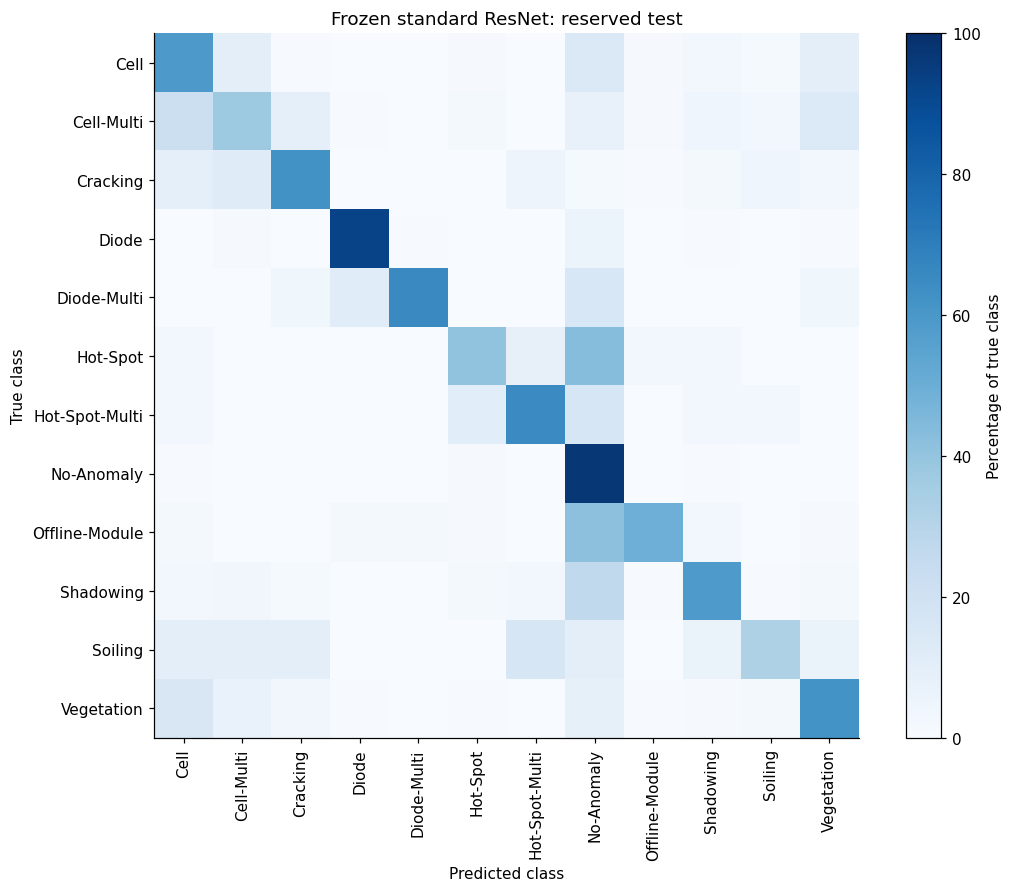

Protocol and evaluation code were frozen in commit: 3ef4040e232ff8e5945c5989153f48401a8a5949
Thresholds remain unchanged. Full records: results/final-evaluation-v1.json


In [7]:
final_path = ROOT / "results/final-evaluation-v1.json"
final = json.loads(final_path.read_text())
protocol_path = ROOT / "configs/final-evaluation-v1.json"
assert final["split"] == "test" and final["test_evaluated"] is True
assert final["protocol_sha256"] == hashlib.sha256(protocol_path.read_bytes()).hexdigest()
final_rows = []
for name, record in final["models"].items():
    metrics, screening = record["multiclass"], record["screening"]
    final_rows.append({"Model": name, "Accuracy": metrics["accuracy"], "Macro-F1": metrics["macro_f1"],
        "Argmax missed faults": metrics["faults_called_normal"],
        "Argmax false alarms": metrics["normal_called_fault"],
        "Screening recall": screening["recall"], "Screening false-alarm rate": screening["false_alarm_rate"]})
display(pd.DataFrame(final_rows).set_index("Model").round(4))
resnet_test = final["models"]["ResNet18"]
display(pd.DataFrame(resnet_test["multiclass"]["per_class"]).T.round(3))
display(pd.DataFrame(resnet_test["intervals"]["bounds"]).T.round(4))
confusion_matrix(resnet_test["multiclass"], "Frozen standard ResNet: reserved test")
print("Protocol and evaluation code were frozen in commit:", final["evaluation_commit"])
print("Thresholds remain unchanged. Full records: results/final-evaluation-v1.json")

### Paired uncertainty in the macro-F1 gap

The individual model intervals overlap, which does not determine uncertainty in their **difference**. We therefore resample the same related-image groups for both models and compute ResNet minus SmallCNN macro-F1 for each draw. This is a post-hoc analysis of saved predictions from the two frozen choices; no images, checkpoints, new inference, model selection or threshold tuning are involved in this comparison.

The gap is **+0.0275**, with a **95% paired group-bootstrap interval of +0.0020 to +0.0524** (1,000 draws, seed 2112, matching the original bootstrap settings). The interval supports a positive gap for these checkpoints on this benchmark. It does not account for training-seed variability, establish independent-site performance, or make ResNet the best operational choice. The observed improvement remains below the proposal draft's +0.05 target, and SmallCNN has substantially lower measured compute cost.

In [8]:
comparison_path = ROOT / "results/final-model-comparison-v1.json"
paired_comparison = json.loads(comparison_path.read_text())
assert paired_comparison["evaluation_results_sha256"] == hashlib.sha256(final_path.read_bytes()).hexdigest()
assert paired_comparison["protocol_sha256"] == final["protocol_sha256"]
assert paired_comparison["new_model_inference"] is False and paired_comparison["model_selection_performed"] is False
gap = paired_comparison["paired_gap"]
display(pd.DataFrame([{"ResNet − CNN macro-F1": gap["observed"], "95% lower": gap["lower"],
                       "95% upper": gap["upper"], "Related-image groups": gap["groups"]}]).round(4))
print(paired_comparison["interpretation"])

,ResNet − CNN macro-F1,95% lower,95% upper,Related-image groups
0,0.0275,0.002,0.0524,2807


The interval is above zero, supporting a positive macro-F1 gap on this benchmark.


## 9. Grad-CAM: inspect selected validation decisions

Grad-CAM weights spatial feature maps by the gradients of a chosen class logit, then keeps positive contributions. We overlay each independently normalised map on the original image. Colour means relative model contribution, **not temperature or calibrated confidence**. See [Selvaraju et al. (2017)](https://arxiv.org/abs/1610.02391).

We use the **unchanged standard augmented ResNet** and choose the lowest image ID in each available category: correct fault, correct normal, missed fault, false alarm and wrong fault subtype. Selection uses saved **validation** predictions only, not attractive heatmaps or test outcomes. Predicted-class and true-class maps are shown side by side; they match for correct predictions. Misses and false alarms here use multiclass argmax, not the separate screening threshold.

**The final feature grid is only 3 × 2.** Enlarging it creates smooth blocks, not precise fault boundaries. These few cases illustrate decisions; they cannot establish causal reasoning, locate faults precisely or measure explanation quality. Zero maps mean no positive contribution under this method, not that the image contains no fault.

If local weights or data are absent, regeneration is skipped; the saved notebook output remains the reviewable record. No training, threshold changes or test-image inference occurs.

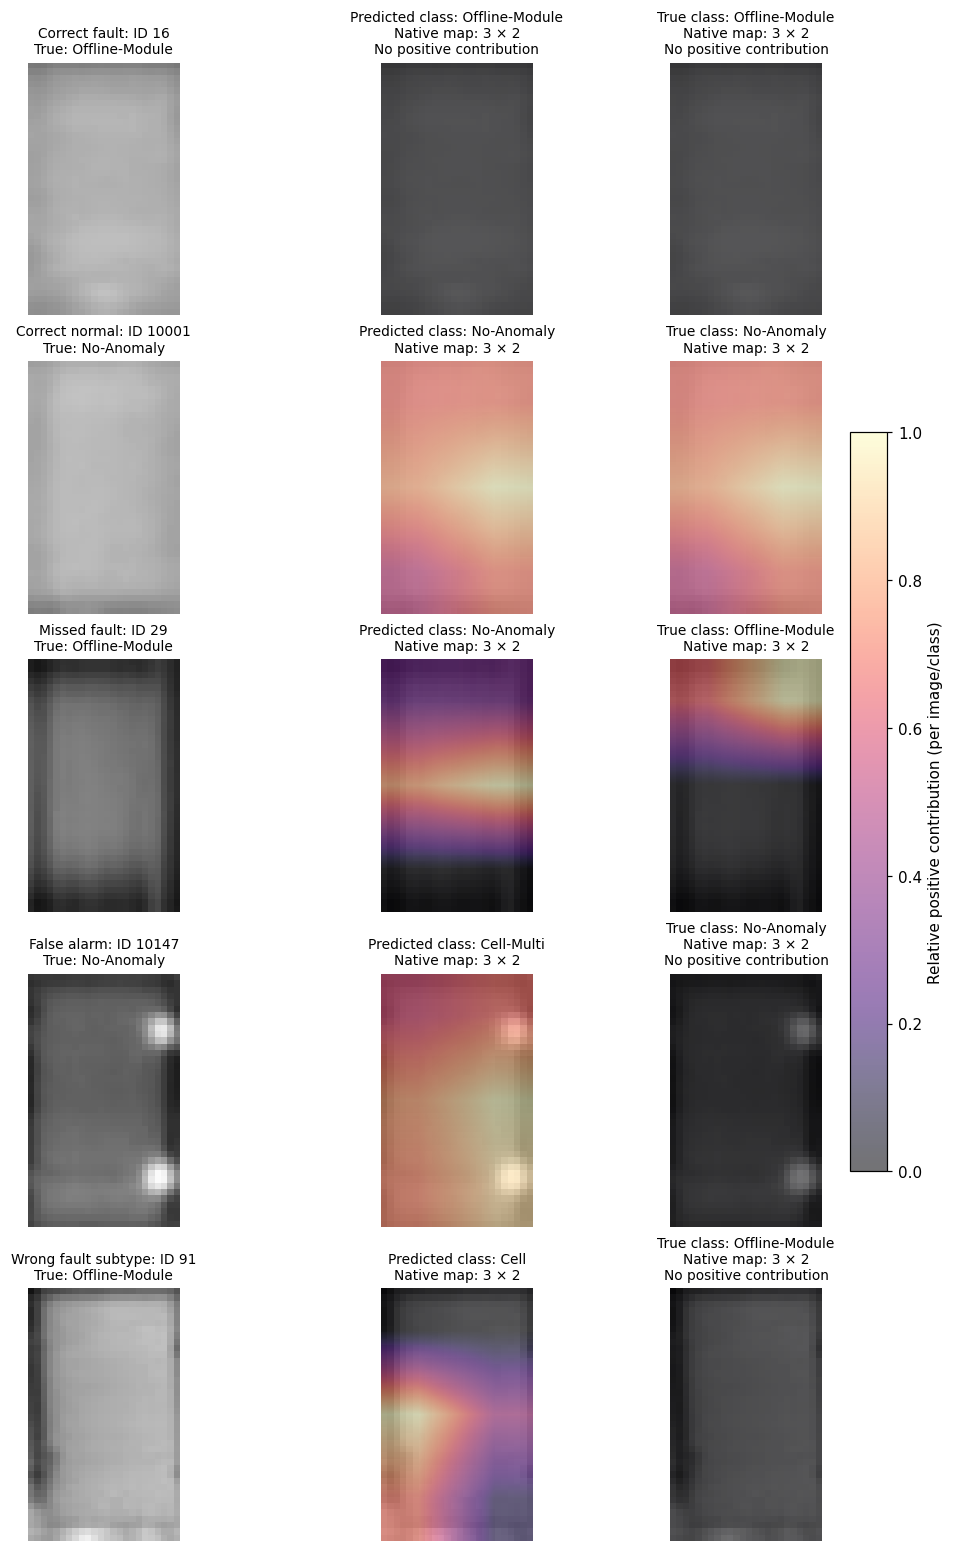

Checkpoint SHA-256: eded6fbc75af2fd1107d2a4e0fd89fa55605b1a679a3c87d666bb321299865f3
Validation examples only; frozen weights and screening thresholds unchanged.


In [9]:
from pv_fault.gradcam import grad_cam
from pv_fault.data import SolarModuleDataset

protocol = json.loads(protocol_path.read_text())
resnet_spec = next(spec for spec in protocol["models"] if spec["name"] == "ResNet18")
run_path = ROOT / "runs" / resnet_spec["run_id"]
needed = [ROOT / path for path in resnet_spec["files"]]
if not all(path.is_file() for path in needed) or not (ROOT / "data/raw/images").is_dir():
    print("Grad-CAM regeneration skipped: prepare local data and retained checkpoints first.")
else:
    sys.path.insert(0, str(ROOT / "scripts"))
    from evaluate_final import load_model
    torch.set_num_threads(4)
    cam_model = load_model(resnet_spec)
    records = json.loads((run_path / "best_validation_predictions.json").read_text())
    normal = CLASS_TO_INDEX["No-Anomaly"]
    categories = {
        "Correct fault": lambda t, p: t == p and t != normal,
        "Correct normal": lambda t, p: t == p == normal,
        "Missed fault": lambda t, p: t != normal and p == normal,
        "False alarm": lambda t, p: t == normal and p != normal,
        "Wrong fault subtype": lambda t, p: t != p and t != normal and p != normal,
    }
    chosen = [(name, next(row for row in sorted(records, key=lambda r: int(r["image_id"]))
                         if predicate(row["true_index"], row["predicted_index"])))
              for name, predicate in categories.items()
              if any(predicate(row["true_index"], row["predicted_index"]) for row in records)]
    val_data = SolarModuleDataset("val", data_root=ROOT / "data", manifest=manifest_path)
    val_by_id = {row["image_id"]: i for i, row in enumerate(val_data.rows)}
    images = []
    for _, row in chosen:
        assert row["image_id"] in val_ids
        index = val_by_id[row["image_id"]]
        assert all(val_data.rows[index][key] == row[key] for key in ("image_path", "group_id"))
        image, label = val_data[index]
        assert label == row["true_index"]
        images.append(image)
    images = torch.stack(images)
    logits, predicted_maps = grad_cam(cam_model, images, cam_model.backbone.layer4,
                                     [row["predicted_index"] for _, row in chosen])
    _, true_maps = grad_cam(cam_model, images, cam_model.backbone.layer4,
                           [row["true_index"] for _, row in chosen])
    assert tuple(predicted_maps.shape[2:]) == (3, 2)
    assert logits.argmax(1).tolist() == [row["predicted_index"] for _, row in chosen]
    # Smaller batches can change CPU floating-point rounding slightly.
    assert torch.allclose(logits.softmax(1), torch.tensor([row["probabilities"] for _, row in chosen]), atol=1e-5, rtol=1e-4)
    assert all(parameter.grad is None for parameter in cam_model.parameters())
    fig, axes = plt.subplots(len(chosen), 3, figsize=(9, 2.8 * len(chosen)), layout="constrained", squeeze=False)
    for i, (category, row) in enumerate(chosen):
        for ax in axes[i]:
            ax.imshow(images[i, 0], cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
        axes[i, 0].set_title(f"{category}: ID {row['image_id']}\nTrue: {CLASS_NAMES[row['true_index']]}", fontsize=9)
        for j, (maps, target) in enumerate(((predicted_maps, row["predicted_index"]), (true_maps, row["true_index"])), 1):
            overlay = axes[i, j].imshow(maps[i, 0], cmap="magma", vmin=0, vmax=1, alpha=.55,
                                       extent=(-.5, 23.5, 39.5, -.5), interpolation="bilinear")
            empty_note = "\nNo positive contribution" if maps[i].count_nonzero() == 0 else ""
            axes[i, j].set_title(f"{'Predicted' if j == 1 else 'True'} class: {CLASS_NAMES[target]}\nNative map: 3 × 2{empty_note}", fontsize=9)
    fig.colorbar(overlay, ax=axes[:, 1:].ravel().tolist(), label="Relative positive contribution (per image/class)", shrink=.5)
    plt.show()
    print("Checkpoint SHA-256:", resnet_spec["files"][str((run_path / "best_model.pt").relative_to(ROOT))])
    print("Validation examples only; frozen weights and screening thresholds unchanged.")

### What these examples show

- Correct Offline-Module example **16** has no positive Grad-CAM map for its predicted class. A correct prediction need not yield a useful positive heatmap.
- For missed fault **29**, the predicted No-Anomaly and true Offline-Module maps emphasise different broad regions. This illustrates class-dependent contributions; it does not establish why the model failed.
- False alarm **10147** is labelled No-Anomaly but predicted Cell-Multi. Its predicted-class map overlaps bright regions; that observation cannot establish a physical fault or a labelling error.

These deliberately selected examples are qualitative checks. The very coarse maps and independently normalised colours prevent precise localisation or comparing contribution strength between images.


## 10. Sensitivity to imperfect thermal crops

A real inspection system must first detect and crop individual panels. This exploratory check asks how the **frozen standard ResNet and its unchanged screening threshold** respond to simulated disturbances of the same **2,988 validation images**. It was conducted after the final test evaluation to investigate an input limitation, not to select a replacement model or threshold.

The eight disturbances were declared before scoring and applied one at a time: 2-pixel translations left/right/up/down, ±5° rotations, Gaussian blur (3 × 3 kernel, sigma 0.75 pixels), and reduction from 40 × 24 to 20 × 12 followed by resizing back. Translations and rotations replicate edge pixels; rotations and resizing use bilinear interpolation, with antialiasing for resizing. A 2-pixel shift is 8.3% of image width or 5% of height. Padding is a simulation and does not reproduce the real background outside a crop.

The unchanged-image pass reproduced **every saved validation probability exactly** before disturbed images were scored. No weights, labels, split assignments or thresholds were changed. Every row uses the same image identities and class supports. Screening recall and false-alarm rate use the frozen binary cutoff; macro-F1 uses multiclass argmax.

,Macro-F1,Screening recall,False-alarm rate,Missed faults,Normal false alarms,Macro-F1 change
Condition,,,,,,
original,0.6281,0.9001,0.0655,149,98,0.0000
shift_left,0.5925,0.8881,0.0689,167,103,-0.0356
shift_right,0.5550,0.8874,0.1217,168,182,-0.0731
shift_up,0.5765,0.8458,0.0468,230,70,-0.0516
shift_down,0.5595,0.8599,0.0668,209,100,-0.0686
rotate_minus5,0.5671,0.9075,0.1090,138,163,-0.0610
rotate_plus5,0.5669,0.8954,0.0782,156,117,-0.0612
blur,0.5964,0.9015,0.0829,147,124,-0.0317
half_resolution,0.5036,0.8338,0.0882,248,132,-0.1245


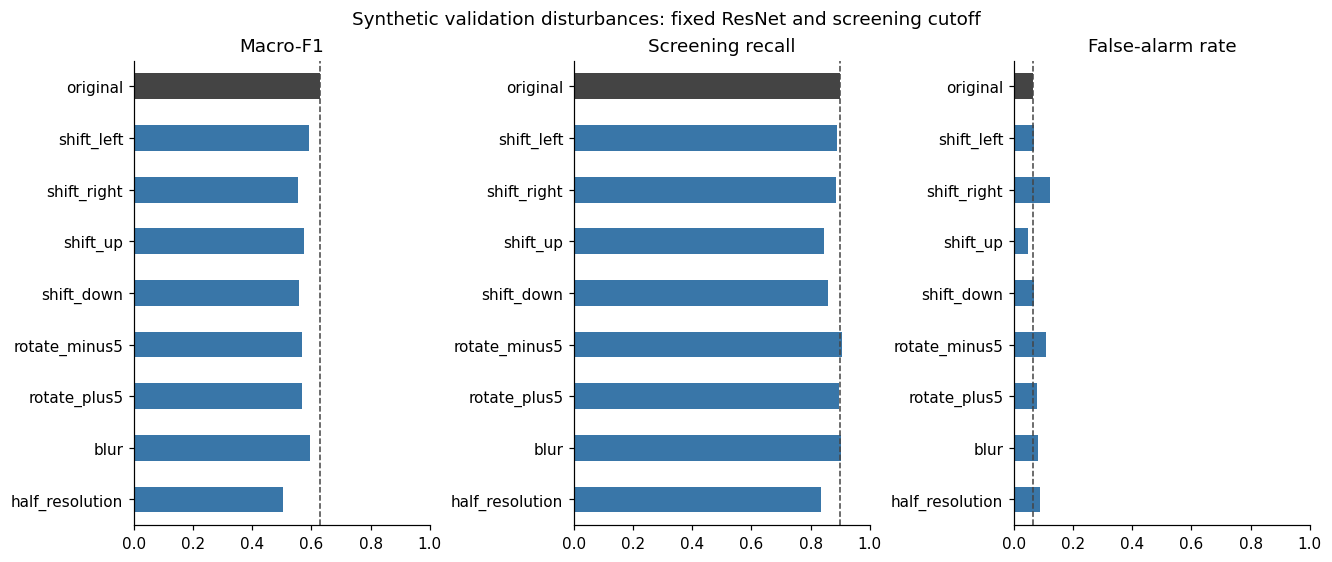

Frozen screening threshold: 0.3929239511489868
Nine validation passes: 3.35 local wall minutes (four CPU threads), excluding setup; no training or test inference.


In [10]:
robustness_path = ROOT / "results/resnet18-validation-robustness-v1.json"
robustness = json.loads(robustness_path.read_text())
assert robustness["split"] == "val" and robustness["test_evaluated"] is False
assert robustness["training_performed"] is False and robustness["original_predictions_verified"]
assert robustness["images_per_condition"] == len(validation_rows)
assert robustness["protocol_sha256"] == hashlib.sha256(protocol_path.read_bytes()).hexdigest()
frozen_resnet = next(spec for spec in json.loads(protocol_path.read_text())["models"] if spec["name"] == "ResNet18")
assert robustness["model"] == frozen_resnet
assert robustness["screening_threshold"] == frozen_resnet["screening"]["threshold"]
robustness_rows = []
for row in robustness["results"]:
    binary = row["screening"]
    robustness_rows.append({"Condition": row["condition"], "Macro-F1": row["macro_f1"],
        "Screening recall": binary["recall"], "False-alarm rate": binary["false_alarm_rate"],
        "Missed faults": binary["missed_faults"], "Normal false alarms": binary["normal_false_alarms"]})
robustness_table = pd.DataFrame(robustness_rows).set_index("Condition")
robustness_table["Macro-F1 change"] = robustness_table["Macro-F1"] - robustness_table.loc["original", "Macro-F1"]
display(robustness_table.round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 5), layout="constrained")
for ax, metric in zip(axes, ["Macro-F1", "Screening recall", "False-alarm rate"]):
    robustness_table[metric].plot.barh(ax=ax, color=["#444444"] + ["#3976a8"] * (len(robustness_table) - 1))
    ax.axvline(robustness_table.loc["original", metric], color="#444444", linestyle="--", linewidth=1)
    ax.set(title=metric, ylabel="", xlim=(0, 1))
    ax.invert_yaxis()
fig.suptitle("Synthetic validation disturbances: fixed ResNet and screening cutoff")
plt.show()
print("Frozen screening threshold:", robustness["screening_threshold"])
print(f"Nine validation passes: {robustness['elapsed_seconds'] / 60:.2f} local wall minutes (four CPU threads), excluding setup; no training or test inference.")

### Interpretation and scope

- **Resolution loss had the largest macro-F1 reduction among the tested conditions:** 0.6281 → 0.5036, with screening recall 90.01% → 83.38%. This demonstrates sensitivity to losing detail in these existing crops; it does not establish the benefit of a different camera.
- **Small alignment changes mattered:** 2-pixel translations produced macro-F1 between 0.5550 and 0.5925, while ±5° rotations produced approximately 0.567. This motivates evaluating crop alignment in a future pipeline.
- **Metrics did not always move together:** blur reduced macro-F1 to 0.5964 while screening recall stayed near 90% and false alarms increased from 6.55% to 8.29%. A single metric would conceal that trade-off.

Original image labels were retained. Some operations remove or obscure fault evidence, and synthetic padding creates border content; the effects cannot be attributed solely to model invariance.

These comparisons measure sensitivity to the specific synthetic disturbances above. They do not estimate deployment performance, establish acceptable camera tolerances, demonstrate a higher-resolution imaging benefit, or show how errors combine. Upsampling cannot recover missing information. We have not measured panel detection, perspective correction, real background intrusion, camera changes or unseen-site performance.

A future pipeline should validate crop alignment and image quality, flag unsuitable inputs for review, and evaluate the complete capture-to-classification process on independent site-labelled data. These simulations motivate that evaluation; they do not define acceptance limits.

To regenerate deliberately with the retained local dataset and checkpoints: `PYTHONPATH=src python scripts/check_validation_robustness.py`. The script refuses to overwrite an existing record. Full per-image predictions remain under the ignored `runs/resnet18-validation-robustness-v1/` folder; the compact [record](../results/resnet18-validation-robustness-v1.json) retains source/checkpoint fingerprints, environment, operation definitions and prediction hashes.